Loading Dataset I...
Dataset I rows: 950
Loading Dataset II...


/tmp/ipykernel_5650/1619150235.py:348: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = np.nan


Dataset II rows: 2222
Combined UV-adVISor rows: 3172
Combined wavelength grid: 220-400 nm (181 points)
Loaded cached combined InChI table: 3170
Loaded cached QM9 structure table: 127047 molecules
Loaded cached Dataset II/QM9 matches: 61 candidate pairs
Unique Dataset II molecules matched: 48
First-block match summary:
  unambiguous Dataset II molecules: 41
  ambiguous Dataset II molecules: 7
  ambiguous matches will be excluded.
Rows remaining after ambiguity filter: 41
QM9 molecules requiring excited-state data: 39
Loaded cached matched QM9 property table: 39
Matched rows with complete QM9 excited-state features: 41

Quarter 3 complete.
Final molecules ready for MACE encoding: 41
QM9 scalar features per molecule: 10 (5 excitation energies + 5 oscillator strengths)
Pre-MACE training table cached:
  /workspaces/pyscf-sandbox/.cache/uvadvisor/qm9gwbse/inputs/matched_training_inputs_b595bbe3b96a.pkl
MACE descriptors already cached: 41/41
MACE descriptors available: 41/41
Symmetry encoding

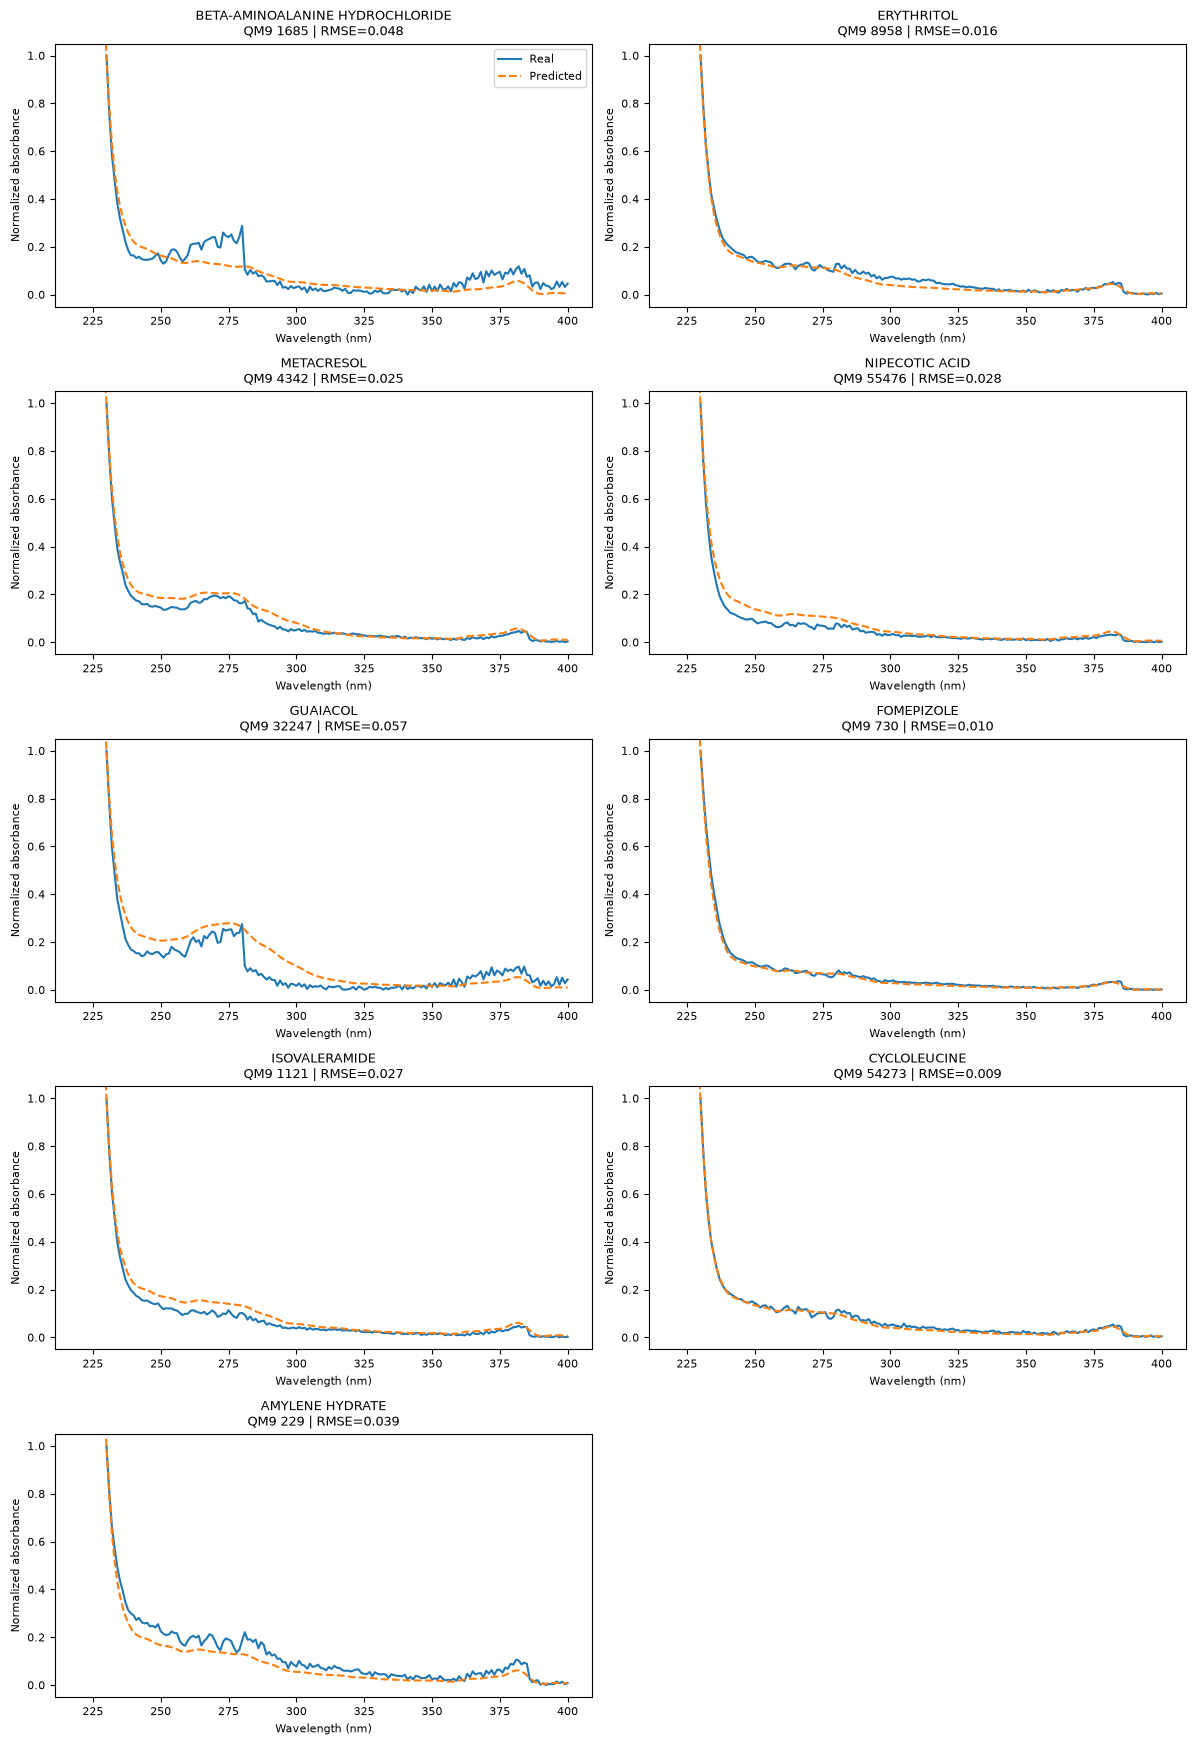

In [17]:
from __future__ import annotations

import hashlib
import os
import pickle
import re
import shutil
import zipfile
from collections import Counter
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import requests

# ============================================================
# RDKIT
# ============================================================

try:
    from rdkit import Chem, RDLogger
    HAVE_RDKIT = True
    RDLogger.DisableLog("rdApp.warning")
    RDLogger.DisableLog("rdApp.error")
except Exception:
    HAVE_RDKIT = False

# ============================================================
# CONFIG
# ============================================================

CACHE_ROOT_ENV = "UVADVISOR_CACHE_ROOT"

CACHE_ROOT = Path(os.environ.get(CACHE_ROOT_ENV, Path.cwd() / ".cache" / "uvadvisor")
).expanduser().resolve()

INPUT_DIR = CACHE_ROOT / "inputs"
OUTPUT_DIR = CACHE_ROOT / "outputs"
DOWNLOAD_DIR = CACHE_ROOT / "downloads"
EXTRACT_DIR = CACHE_ROOT / "extracted"

QM9_ROOT = CACHE_ROOT / "qm9gwbse"
QM9_DOWNLOAD_DIR = QM9_ROOT / "downloads"
QM9_INPUT_DIR = QM9_ROOT / "inputs"

for directory in (INPUT_DIR, OUTPUT_DIR, DOWNLOAD_DIR, EXTRACT_DIR, QM9_DOWNLOAD_DIR, QM9_INPUT_DIR
):
    directory.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOCAL DATASET FILES
# ============================================================

DATASET1_CSV = INPUT_DIR / "Dataset_I.csv"

DATASET2_CSV = INPUT_DIR / "Dataset_II.csv"

# IMPORTANT:
# New cache filename so the old Dataset-II-only cache
# cannot accidentally be reused.
DATASET2_TABLE_CACHE = INPUT_DIR / "dataset1_dataset2_inchi_first_block_table.pkl"

QM9_XYZ_TABLE_CACHE = QM9_INPUT_DIR / "qm9_xyz_inchi_first_block_table.pkl"

PREVIEW_PATH = OUTPUT_DIR / "combined_dataset_first5_long.csv"

# ============================================================
# FIGSHARE SOURCE
# ============================================================

FIGSHARE_FILE_ID = 31512017

FIGSHARE_DOWNLOAD_URL = f"https://ndownloader.figshare.com/files/" f"{FIGSHARE_FILE_ID}"

FIGSHARE_ZIP_NAME = "Paper supplementary data 2.zip"

# ============================================================
# QM9 CONFIG
# ============================================================

ZENODO_RECORD_ID = 17902233

QM9_REQUIRED_ZIPS = {"xyz": "xyz.zip", "eexc_ss": "eexc_ss.zip", "osc_stren": "osc_stren.zip"}

N_QM9_FEATURES = 5

MAX_MATCHED_MOLECULES = None

# ============================================================
# TARGET WAVELENGTH GRID
# ============================================================

# Dataset I:
#   V1   = 220 nm
#   V2   = 221 nm
#   ...
#   V181 = 400 nm
#
# Dataset II:
#   230 ... 400 nm
#
# We retain the UNION:
#   220 ... 400 nm
#
# Dataset II gets NaN at 220-229 nm.

WAVELENGTH_MIN = 220
WAVELENGTH_MAX = 400

ALL_WAVELENGTHS = list(range(WAVELENGTH_MIN, WAVELENGTH_MAX + 1))

ALL_WAVELENGTH_COLS = [str(w) for w in ALL_WAVELENGTHS]

# ============================================================
# GENERIC HELPERS
# ============================================================


def write_pickle(obj, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("wb") as f:
        pickle.dump(obj, f)
    return path


def read_pickle(path: Path):
    with path.open("rb") as f:
        return pickle.load(f)


def hash_id_set(ids: set[str]) -> str:
    joined = ",".join(sorted(ids)).encode("utf-8")
    return hashlib.sha1(joined).hexdigest()[:12]


def download_file(url: str, destination: Path) -> Path:
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        return destination
    with requests.get(url, stream=True, timeout=180) as response:
        response.raise_for_status()
        with destination.open("wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    return destination


def extract_zip(zip_path: Path, output_dir: Path) -> Path:
    target = output_dir / zip_path.stem
    if target.exists():
        return target
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(target)
    return target

# ============================================================
# INCHI HELPERS
# ============================================================


def inchi_first_block(inchi_key: Optional[str]) -> Optional[str]:
    """
    Extract the first 14-character connectivity block.

    Example:

        UHOVQNZJYSORNB-UHFFFAOYSA-N

    becomes:

        UHOVQNZJYSORNB
    """
    if not inchi_key:
        return None
    if not isinstance(inchi_key, str):
        return None
    block = inchi_key.strip().split("-")[0]
    if not block:
        return None
    return block


def smiles_to_inchi_key(smiles: str) -> Optional[str]:
    if not HAVE_RDKIT:
        raise RuntimeError("RDKit is required for " "SMILES -> InChIKey conversion.")
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None
        key = Chem.MolToInchiKey(mol)
        if not key:
            return None
        return key
    except Exception:
        return None

# ============================================================
# DOWNLOAD / LOCATE DATASETS I + II
# ============================================================


def ensure_uvadvisor_csvs():
    """
    Ensure both Dataset_I.csv and Dataset_II.csv exist locally.

    They come from the same Figshare supplementary archive.
    """
    if DATASET1_CSV.exists() and DATASET2_CSV.exists():
        return (DATASET1_CSV.resolve(), DATASET2_CSV.resolve())
    zip_path = DOWNLOAD_DIR / FIGSHARE_ZIP_NAME
    if not zip_path.exists():
        print("Downloading UV-adVISor supplementary data...")
        download_file(FIGSHARE_DOWNLOAD_URL, zip_path)
    print("Locating Dataset I and Dataset II...")
    extract_root = extract_zip(zip_path, EXTRACT_DIR)

    # --------------------------------------
    # Dataset I
    # --------------------------------------

    if not DATASET1_CSV.exists():
        candidates1 = list(extract_root.rglob("Dataset_I.csv"))
        if not candidates1:
            raise FileNotFoundError("Could not locate Dataset_I.csv "
                "inside the extracted Figshare archive.")
        shutil.copy2(candidates1[0], DATASET1_CSV)

    # --------------------------------------
    # Dataset II
    # --------------------------------------

    if not DATASET2_CSV.exists():
        candidates2 = list(extract_root.rglob("Dataset_II.csv"))
        if not candidates2:

            # Retain old fallback spelling.
            candidates2 = list(extract_root.rglob("Dataset_2.csv"))
        if not candidates2:
            raise FileNotFoundError("Could not locate Dataset_II.csv "
                "inside the extracted Figshare archive.")
        shutil.copy2(candidates2[0], DATASET2_CSV)
    return (DATASET1_CSV.resolve(), DATASET2_CSV.resolve())

# ============================================================
# DATASET I
# ============================================================


def load_dataset1(csv_path: Path) -> pd.DataFrame:
    """
    Load Dataset I.

    Dataset I uses:

        V1  -> 220 nm
        V2  -> 221 nm
        ...
        V181 -> 400 nm

    The V-columns are renamed to actual wavelength strings.
    """
    df = pd.read_csv(csv_path)
    df.columns = [str(c).strip() for c in df.columns]
    required = {"Molecule_ID", "SMILES"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError("Dataset I is missing required columns: " f"{sorted(missing)}")

    # --------------------------------------
    # Find V1, V2, ...
    # --------------------------------------

    v_columns = []
    for col in df.columns:
        match = re.fullmatch(r"V(\d+)", col)
        if match:
            index = int(match.group(1))
            v_columns.append((index, col))
    if not v_columns:
        raise ValueError("Dataset I contains no V1/V2/... " "spectral columns.")
    v_columns.sort(key=lambda x: x[0])

    # --------------------------------------
    # Rename Vn -> wavelength
    #
    # V1 = 220
    # therefore wavelength = 219 + n
    # --------------------------------------

    rename_map = {}
    for index, old_name in v_columns:
        wavelength = 219 + index
        if wavelength < WAVELENGTH_MIN or wavelength > WAVELENGTH_MAX:
            continue
        rename_map[old_name] = str(wavelength)
    df = df.rename(columns=rename_map)

    # --------------------------------------
    # Ensure all wavelengths exist
    # --------------------------------------

    for col in ALL_WAVELENGTH_COLS:
        if col not in df.columns:
            df[col] = np.nan
    for col in ALL_WAVELENGTH_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Keep just the useful fields.
    df = df[["Molecule_ID", "SMILES", *ALL_WAVELENGTH_COLS]].copy()
    df["source_dataset"] = "Dataset_I"
    return df

# ============================================================
# DATASET II
# ============================================================


def load_dataset2_only(csv_path: Path) -> pd.DataFrame:
    """
    Load Dataset II.

    Dataset II already uses numeric column names:

        230
        231
        ...
        400

    Columns 220-229 are added as NaN so that Dataset I
    and Dataset II share the same spectrum width.
    """
    df = pd.read_csv(csv_path)
    df.columns = [str(c).strip() for c in df.columns]
    required = {"Molecule_ID", "SMILES"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError("Dataset II is missing required columns: " f"{sorted(missing)}")

    # --------------------------------------
    # Add absent wavelengths as NaN
    # --------------------------------------

    for col in ALL_WAVELENGTH_COLS:
        if col not in df.columns:
            df[col] = np.nan
    for col in ALL_WAVELENGTH_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df[["Molecule_ID", "SMILES", *ALL_WAVELENGTH_COLS]].copy()
    df["source_dataset"] = "Dataset_II"
    return df

# ============================================================
# COMBINE DATASET I + II
# ============================================================


def load_dataset2(csv_paths=None):
    """
    Compatibility function.

    The rest of the existing script expects:

        df, wavelength_cols = load_dataset2(...)

    so we KEEP that API, but it now loads and combines
    Dataset I + Dataset II.

    Resulting wavelength grid:

        220 ... 400 nm

    Dataset II rows have NaN at 220-229 nm.
    """
    if csv_paths is None:
        dataset1_path, dataset2_path = ensure_uvadvisor_csvs()
    else:
        dataset1_path, dataset2_path = csv_paths
    print("Loading Dataset I...")
    df1 = load_dataset1(dataset1_path)
    print(f"Dataset I rows: {len(df1)}")
    print("Loading Dataset II...")
    df2 = load_dataset2_only(dataset2_path)
    print(f"Dataset II rows: {len(df2)}")

    # --------------------------------------
    # Append them vertically
    # --------------------------------------

    combined = pd.concat([df1, df2], axis=0, ignore_index=True, sort=False)
    print("Combined UV-adVISor rows: " f"{len(combined)}")
    print("Combined wavelength grid: " f"{WAVELENGTH_MIN}-" f"{WAVELENGTH_MAX} nm "
        f"({len(ALL_WAVELENGTH_COLS)} points)")
    return (combined, ALL_WAVELENGTH_COLS.copy())

# ============================================================
# LONG-FORM PREVIEW
# ============================================================


def to_long_format(df: pd.DataFrame, wavelength_cols: list[str]) -> pd.DataFrame:
    id_columns = ["Molecule_ID", "SMILES"]
    if "source_dataset" in df.columns:
        id_columns.append("source_dataset")
    long_df = df.melt(id_vars=id_columns, value_vars=wavelength_cols, var_name="wavelength_nm",
        value_name="absorbance_norm")
    long_df["wavelength_nm"] = pd.to_numeric(long_df["wavelength_nm"], errors="coerce")
    return long_df

# ============================================================
# BUILD COMBINED INCHI TABLE
# ============================================================


def build_dataset2_inchi_table(df: pd.DataFrame, wavelength_cols: list[str]) -> pd.DataFrame:
    """
    Convert the combined Dataset I + Dataset II rows into:

        name
        source_dataset
        smiles
        full InChIKey
        first InChIKey block
        spectrum

    The function keeps its old name so quarters 2-4 do not
    need to be rewritten.
    """
    if DATASET2_TABLE_CACHE.exists():
        cached = read_pickle(DATASET2_TABLE_CACHE)
        print("Loaded cached combined " f"InChI table: {len(cached)}")
        return cached
    total = len(df)
    rows = []
    checked = 0
    successful_inchi = 0
    failed_inchi = 0
    print("Generating Dataset I + II InChIKeys...")
    for _, row in df.iterrows():
        checked += 1
        name = str(row["Molecule_ID"]).strip()
        smiles = str(row["SMILES"]).strip()
        source_dataset = str(row.get("source_dataset", "unknown"))
        spectrum = row[wavelength_cols].to_numpy(dtype=float)

        # Skip only if the entire spectrum is missing.
        if np.isnan(spectrum).all():
            continue
        inchi_key = smiles_to_inchi_key(smiles)
        if not inchi_key:
            failed_inchi += 1
        else:
            successful_inchi += 1
            rows.append({"name": name,
"source_dataset": source_dataset,
"smiles": smiles,
"inchi_key": inchi_key,
"inchi_first_block": inchi_first_block(inchi_key),
"spectrum": spectrum.astype(float)})
        if checked == 1 or checked % 100 == 0 or checked == total:
            print(f"Combined dataset checked: " f"{checked}/{total} | " f"InChI success: "
                f"{successful_inchi} | " f"failed: " f"{failed_inchi}")
    result = pd.DataFrame(rows)
    if result.empty:
        raise RuntimeError("No Dataset I/II molecules " "could be converted to InChIKeys.")
    result = result.dropna(subset=["inchi_first_block"]).reset_index(drop=True)
    write_pickle(result, DATASET2_TABLE_CACHE)
    print()
    print("Combined InChI table cached: " f"{len(result)} molecules")
    print("Dataset I molecules retained: " f"{(result['source_dataset'] == 'Dataset_I').sum()}")
    print("Dataset II molecules retained: " f"{(result['source_dataset'] == 'Dataset_II').sum()}")
    print("Unique connectivity blocks: " f"{result['inchi_first_block'].nunique()}")
    return result

# ============================================================
# QUARTER 1 ENTRYPOINT
# ============================================================


def prepare_dataset2():
    """
    Compatibility entrypoint for the existing quarters 2-4.

    Despite retaining the old function name, this now prepares:

        Dataset I
        +
        Dataset II

    on a single 220-400 nm wavelength grid.
    """
    dataset1_path, dataset2_path = ensure_uvadvisor_csvs()
    combined_df, wavelength_cols = load_dataset2((dataset1_path, dataset2_path))

    # --------------------------------------
    # Small preview
    # --------------------------------------

    to_long_format(combined_df.head(5), wavelength_cols).to_csv(PREVIEW_PATH, index=False)
    combined_inchi_df = build_dataset2_inchi_table(combined_df, wavelength_cols)

    # Keep four return values so quarter 4's main()
    # continues to work unchanged.
    #
    # The first value is now a tuple of both source paths.
    csv_paths = dataset1_path, dataset2_path
    return (csv_paths, combined_df, wavelength_cols, combined_inchi_df)

# ============================================================
# END OF QUARTER 1
# ============================================================

# Quarter 2 can consume combined_inchi_df exactly as before.
#
# The spectrum arrays are now length 181:
#
#     220 ... 400 nm
#
# Dataset II rows contain NaN at 220 ... 229 nm.
#
# The per-wavelength Random Forest in quarter 4 already trains
# only on non-NaN targets, so no special interpolation or
# artificial values are required.

# ============================================================
# ADDITIONAL CACHE
# ============================================================

MATCHED_TABLE_CACHE = INPUT_DIR / "dataset1_dataset2_qm9_first_block_matches.pkl"

# ============================================================
# DOWNLOAD QM9 ARCHIVES
# ============================================================


def get_zenodo_file_table() -> dict:
    """
    Retrieve the Zenodo record metadata once per call.

    The actual ZIP files themselves are cached locally, so they
    will not be downloaded again if already present.
    """
    record_api = f"https://zenodo.org/api/records/" f"{ZENODO_RECORD_ID}"
    response = requests.get(record_api, timeout=180)
    response.raise_for_status()
    data = response.json()
    files = data.get("files", [])
    by_name = {}
    for file_info in files:
        name = file_info.get("key") or file_info.get("name")
        if name:
            by_name[name] = file_info
    return by_name


def get_zenodo_download_url(file_info: dict) -> str:
    """
    Extract a usable download URL from Zenodo metadata.
    """
    links = file_info.get("links")
    if isinstance(links, dict):
        url = links.get("download") or links.get("self")
        if url:
            return url
    url = file_info.get("download_url") or file_info.get("url")
    if not url:
        raise RuntimeError("Could not determine a download " "URL from the Zenodo file metadata.")
    return url


def ensure_qm9_xyz_zip() -> Path:
    """
    Ensure xyz.zip is available locally.

    Importantly, this only downloads xyz.zip at this stage.
    Excitation energies and oscillator strengths are deliberately
    postponed until AFTER the Dataset II/QM9 matching step.
    """
    destination = QM9_DOWNLOAD_DIR / QM9_REQUIRED_ZIPS["xyz"]
    if destination.exists() and destination.stat().st_size > 0:
        print("Using cached QM9 xyz.zip.")
        return destination.resolve()
    print("Downloading QM9 xyz.zip...")
    file_table = get_zenodo_file_table()
    filename = QM9_REQUIRED_ZIPS["xyz"]
    if filename not in file_table:
        raise FileNotFoundError(f"Zenodo record {ZENODO_RECORD_ID} " f"does not contain {filename}."
        )
    url = get_zenodo_download_url(file_table[filename])
    download_file(url, destination)
    print("QM9 xyz.zip downloaded.")
    return destination.resolve()

# ============================================================
# QM9 XYZ PARSING
# ============================================================


def xyz_atoms_to_inchi_key(atoms: list[tuple[str, list[float]]]) -> Optional[str]:
    """
    Convert an XYZ geometry into an InChIKey.

    XYZ files do not contain bond connectivity, so RDKit must infer
    bonds from the coordinates before an InChIKey can be generated.

    Failures simply return None and do not stop the pipeline.
    """
    if not HAVE_RDKIT:
        raise RuntimeError("RDKit is required for " "XYZ -> InChIKey conversion.")
    try:
        xyz_lines = [str(len(atoms)), ""]
        for symbol, coords in atoms:
            x, y, z = coords
            xyz_lines.append(f"{symbol} " f"{x:.10f} " f"{y:.10f} " f"{z:.10f}")
        xyz_block = "\n".join(xyz_lines) + "\n"
        mol = Chem.MolFromXYZBlock(xyz_block)
        if mol is None:
            return None

        # Infer molecular connectivity from the geometry.
        try:
            from rdkit.Chem import (rdDetermineBonds)
            rdDetermineBonds.DetermineBonds(mol, charge=0)
        except Exception:
            return None
        try:
            mol = Chem.RemoveHs(mol)
        except Exception:
            pass
        try:
            key = Chem.MolToInchiKey(mol)
        except Exception:
            return None
        if not key:
            return None
        return key
    except Exception:
        return None


def parse_qm9_xyz_member(raw: bytes) -> Optional[dict]:
    """
    Parse one QM9 .xyz member.

    Returns:
        {
            natoms,
            atoms,
            formula,
            comment
        }

    or None on malformed data.
    """
    try:
        text = raw.decode("utf-8", errors="ignore")
    except Exception:
        return None
    lines = [line.rstrip() for line in text.splitlines()]
    if len(lines) < 2:
        return None
    try:
        natoms_expected = int(lines[0].strip())
    except Exception:
        return None
    comment = lines[1].strip()
    atom_lines = lines[2: 2 + natoms_expected]
    atoms = []
    atom_symbols = []
    for line in atom_lines:
        parts = line.split()
        if len(parts) < 4:
            continue
        symbol = parts[0]
        try:
            x = float(parts[1])
            y = float(parts[2])
            z = float(parts[3])
        except ValueError:
            continue
        atoms.append((symbol, [x, y, z]))
        atom_symbols.append(symbol)
    if not atoms:
        return None
    formula = hill_formula_from_atoms(atom_symbols)
    return {"natoms": len(atoms),
"comment": comment,
"atoms": atoms,
"formula": formula}

# ============================================================
# BUILD QM9 INCHI TABLE
# ============================================================


def build_qm9_xyz_inchi_table(force_rebuild: bool = False) -> pd.DataFrame:
    """
    Build the cached QM9 structure table:

        qm9_id
        inchi_key
        inchi_first_block
        formula
        natoms
        qm9_atoms

    The expensive XYZ -> InChI conversion is therefore only
    required once.
    """
    if QM9_XYZ_TABLE_CACHE.exists() and not force_rebuild:
        table = read_pickle(QM9_XYZ_TABLE_CACHE)

        # Repair an older cache automatically.
        if "inchi_first_block" not in table.columns and "inchi_key" in table.columns:
            table = table.copy()
            table["inchi_first_block"] = table["inchi_key"].map(inchi_first_block)
            write_pickle(table, QM9_XYZ_TABLE_CACHE)
        print("Loaded cached QM9 structure table: " f"{len(table)} molecules")
        return table
    xyz_zip = ensure_qm9_xyz_zip()
    rows = []
    checked = 0
    parsed = 0
    successful_inchi = 0
    failed_inchi = 0
    print("Generating QM9 InChIKeys " "from xyz structures...")
    with zipfile.ZipFile(xyz_zip, "r") as zf:
        names = [name for name in zf.namelist() if (Path(name).name.startswith("mol_")
                and Path(name).name.endswith(".xyz"))]
        total = len(names)
        for name in names:
            checked += 1
            try:
                raw = zf.read(name)
            except Exception:
                continue
            rec = parse_qm9_xyz_member(raw)
            if rec is None:
                continue
            parsed += 1
            inchi_key = xyz_atoms_to_inchi_key(rec["atoms"])
            if not inchi_key:
                failed_inchi += 1
            else:
                successful_inchi += 1
                rows.append({"qm9_id": int(normalize_mol_id(name)),
"inchi_key": inchi_key,
"inchi_first_block": inchi_first_block(inchi_key),
"formula": rec["formula"],
"natoms": rec["natoms"],
"qm9_comment": rec["comment"],
"qm9_atoms": rec["atoms"]})
            if checked == 1 or checked % 5000 == 0 or checked == total:
                print(f"QM9 xyz checked: " f"{checked}/{total} | " f"InChI success: "
                    f"{successful_inchi} | " f"failed: " f"{failed_inchi}")
    table = pd.DataFrame(rows)
    if table.empty:
        raise RuntimeError("No QM9 structures could " "be converted to InChIKeys.")
    table = table.dropna(subset=["inchi_first_block"]).reset_index(drop=True)
    write_pickle(table, QM9_XYZ_TABLE_CACHE)
    print("QM9 structure table cached: " f"{len(table)} molecules")
    print("Unique QM9 first-block identifiers: " f"{table['inchi_first_block'].nunique()}")
    return table

# ============================================================
# FIRST-BLOCK MATCHING
# ============================================================


def match_dataset2_to_qm9(dataset2_df: pd.DataFrame, qm9_df: pd.DataFrame,
    force_rebuild: bool = False) -> pd.DataFrame:
    """
    Match Dataset II and QM9 using ONLY the first InChIKey block.

    Progress is reported from the Dataset II perspective.

    Note:
    A first-block match identifies matching connectivity, but
    multiple QM9 rows can theoretically share the same block.
    Those ambiguities are kept and reported rather than silently
    choosing one.
    """
    if MATCHED_TABLE_CACHE.exists() and not force_rebuild:
        matched = read_pickle(MATCHED_TABLE_CACHE)
        print("Loaded cached Dataset II/QM9 matches: " f"{len(matched)} candidate pairs")
        if "dataset2_row_id" in matched.columns:
            print("Unique Dataset II molecules matched: " f"{matched['dataset2_row_id'].nunique()}")
        return matched
    dataset2_df = dataset2_df.copy().reset_index(drop=True)
    qm9_df = qm9_df.copy().reset_index(drop=True)

    # Stable Dataset II row identifier.
    dataset2_df["dataset2_row_id"] = np.arange(len(dataset2_df), dtype=int)

    # --------------------------------------
    # Build a very cheap lookup set.
    # --------------------------------------

    qm9_blocks = set(qm9_df["inchi_first_block"].dropna().astype(str))
    total = len(dataset2_df)
    checked = 0
    successful = 0
    matched_row_ids = []
    print("Checking Dataset II molecules " "against QM9 connectivity blocks...")
    for _, row in dataset2_df.iterrows():
        checked += 1
        block = row.get("inchi_first_block")
        if pd.notna(block) and str(block) in qm9_blocks:
            successful += 1
            matched_row_ids.append(int(row["dataset2_row_id"]))
        if checked == 1 or checked % 100 == 0 or checked == total:
            print(f"Dataset II match check: " f"{checked}/{total} | " f"successful: "
                f"{successful}")

    # Restrict before doing the actual merge.
    dataset2_matched = dataset2_df[dataset2_df["dataset2_row_id"].isin(matched_row_ids)].copy()

    # --------------------------------------
    # Actual first-block join.
    # --------------------------------------

    matched = (dataset2_matched.merge(qm9_df, on="inchi_first_block", how="inner", suffixes=(
                "_dataset2", "_qm9")))

    # --------------------------------------
    # Diagnostics
    # --------------------------------------

    unique_dataset2_matches = matched["dataset2_row_id"].nunique()
    unique_qm9_matches = matched["qm9_id"].nunique()
    pair_count = len(matched)
    candidate_counts = matched.groupby("dataset2_row_id")["qm9_id"].nunique()
    ambiguous_dataset2 = int((candidate_counts > 1).sum())
    one_to_one_dataset2 = int((candidate_counts == 1).sum())
    print()
    print("First-block matching complete.")
    print("Dataset II molecules matched: " f"{unique_dataset2_matches}")
    print("Unique QM9 molecules involved: " f"{unique_qm9_matches}")
    print("Total Dataset II-QM9 candidate pairs: " f"{pair_count}")
    print("Dataset II molecules with exactly " f"one QM9 candidate: {one_to_one_dataset2}")
    print("Dataset II molecules with multiple " f"QM9 candidates: {ambiguous_dataset2}")
    print("\nMatched molecules by source dataset:")
    print(matched_df["source_dataset"].value_counts())
    print("\nUnique matched experimental molecules by source:")
    print(matched_df.groupby("source_dataset")["dataset2_row_id"].nunique())

    # --------------------------------------
    # Optional user limit
    # --------------------------------------

    if MAX_MATCHED_MOLECULES is not None:
        keep_dataset_rows = (matched["dataset2_row_id"].drop_duplicates().head(MAX_MATCHED_MOLECULES
            ))
        matched = matched[matched["dataset2_row_id"].isin(keep_dataset_rows)].copy()
        print("Matches retained after " f"MAX_MATCHED_MOLECULES limit: "
            f"{matched['dataset2_row_id'].nunique()}")
    write_pickle(matched, MATCHED_TABLE_CACHE)
    print("Match table cached at:")
    print(f"  {MATCHED_TABLE_CACHE}")
    return matched

# ============================================================
# QUARTER 2 ENTRYPOINT
# ============================================================


def prepare_qm9_and_matches(dataset2_inchi_df: pd.DataFrame):
    """
    Run the second quarter of the pipeline.

    Input:
        dataset2_inchi_df from prepare_dataset2()

    Returns:
        qm9_xyz_df
        matched_df
    """
    qm9_xyz_df = build_qm9_xyz_inchi_table()
    matched_df = match_dataset2_to_qm9(dataset2_inchi_df, qm9_xyz_df)
    return (qm9_xyz_df, matched_df)

# ============================================================
# EXAMPLE CONNECTION BETWEEN QUARTER 1 AND QUARTER 2
# ============================================================

# Run these only when you are ready to execute the pipeline:
#
# (
#     csv_path,
#     dataset2_raw_df,
#     wavelength_cols,
#     dataset2_inchi_df,
# ) = prepare_dataset2()
#
# (
#     qm9_xyz_df,
#     matched_df,
# ) = prepare_qm9_and_matches(
#     dataset2_inchi_df
# )

# ============================================================
# END OF QUARTER 2
# ============================================================

# Quarter 3 will:
#
# 1. take matched_df
# 2. identify only the required QM9 molecule IDs
# 3. download/reuse eexc_ss.zip and osc_stren.zip
# 4. read ONLY mol_<matched ID>.dat entries
# 5. add the first 5 excitation energies
# 6. add the first 5 oscillator strengths
# 7. cache the resulting training-input table

# ============================================================
# QUARTER 3
# MATCHED QM9 IDs -> EXCITATION ENERGIES + OSCILLATOR STRENGTHS
# ============================================================

# ============================================================
# CONFIG FOR FIRST-BLOCK AMBIGUITIES
# ============================================================

# First-block matching ignores stereochemical / other InChI layers.
# Occasionally one Dataset II molecule can therefore match multiple
# QM9 structures.
#
# False = safest choice:
#         train only on Dataset II molecules with one QM9 candidate.
#
# True  = retain all candidate QM9 structures.
KEEP_AMBIGUOUS_MATCHES = False

# ============================================================
# PROPERTY ZIP DOWNLOAD
# ============================================================


def ensure_qm9_property_zips() -> dict[str, Path]:
    """
    Ensure the two QM9GWBSE property archives required for training
    are available:

        eexc_ss.zip
        osc_stren.zip

    xyz.zip was handled in quarter 2.

    These files are downloaded only now, after matching.
    """
    required = {"eexc_ss": QM9_REQUIRED_ZIPS["eexc_ss"],
"osc_stren": QM9_REQUIRED_ZIPS["osc_stren"]}
    paths = {}
    missing = []

    # --------------------------------------
    # Check local cache first
    # --------------------------------------

    for property_name, filename in required.items():
        destination = QM9_DOWNLOAD_DIR / filename
        if destination.exists() and destination.stat().st_size > 0:
            paths[property_name] = destination.resolve()
        else:
            missing.append((property_name, filename, destination))

    # Everything already cached.
    if not missing:
        print("Using cached QM9 excitation " "and oscillator-strength archives.")
        return paths

    # --------------------------------------
    # Query Zenodo only if something missing
    # --------------------------------------

    file_table = get_zenodo_file_table()
    for (property_name, filename, destination) in missing:
        if filename not in file_table:
            raise FileNotFoundError(f"Zenodo record " f"{ZENODO_RECORD_ID} " f"does not contain "
                f"{filename}.")
        print(f"Downloading {filename}...")
        url = get_zenodo_download_url(file_table[filename])
        download_file(url, destination)
        print(f"{filename} downloaded.")
        paths[property_name] = destination.resolve()
    return paths

# ============================================================
# PROPERTY ZIP MEMBER FILTER
# ============================================================


def is_qm9_property_member(name: str) -> bool:
    """
    Return True only for genuine QM9 mol_*.dat property members.

    This deliberately excludes things such as:

        osc_stren/.zip

    which previously caused binary data to be parsed as floats.
    """
    base = Path(name).name
    return bool(re.fullmatch(r"mol_\d+\.dat", base))

# ============================================================
# LOAD ONLY MATCHED PROPERTY ROWS
# ============================================================


def load_property_zip_for_ids(zip_path: Path, keep_ids: set[str], property_label: str
) -> dict[str, np.ndarray]:
    """
    Read property values only for the requested QM9 molecule IDs.

    The archive directory is scanned, but only matching mol_*.dat
    files are actually decompressed and parsed.
    """
    keep_ids = {str(int(x)) for x in keep_ids}
    values = {}
    print(f"Reading matched {property_label}...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [name for name in zf.namelist() if is_qm9_property_member(name)]
        total_members = len(members)
        checked = 0
        found = 0
        for name in members:
            checked += 1
            qm9_id = normalize_mol_id(name)

            # Do not decompress irrelevant files.
            if qm9_id not in keep_ids:
                if checked % 25000 == 0 or checked == total_members:
                    print(f"  {property_label}: " f"scanned " f"{checked}/{total_members} | "
                        f"found " f"{found}/{len(keep_ids)}")
                continue
            try:
                raw = zf.read(name)
            except Exception:
                continue
            arr = parse_text_numbers(raw)
            if arr.size == 0:
                continue
            values[qm9_id] = arr
            found += 1

            # If every requested ID has been found,
            # there is no reason to keep scanning.
            if found == len(keep_ids):
                print(f"  {property_label}: " f"found all " f"{found}/{len(keep_ids)} "
                    f"requested molecules.")
                break
            if checked % 25000 == 0:
                print(f"  {property_label}: " f"scanned " f"{checked}/{total_members} | " f"found "
                    f"{found}/{len(keep_ids)}")
    print(f"{property_label} rows loaded: " f"{len(values)}/{len(keep_ids)}")
    return values

# ============================================================
# HANDLE FIRST-BLOCK AMBIGUITIES
# ============================================================


def filter_first_block_matches(matched_df: pd.DataFrame) -> pd.DataFrame:
    """
    Optionally remove Dataset II molecules that matched more than
    one QM9 molecule through the first InChIKey block.

    This prevents one experimental spectrum from being silently
    duplicated across several structural candidates.
    """
    matched_df = matched_df.copy().reset_index(drop=True)
    if "dataset2_row_id" not in matched_df.columns:
        raise ValueError("matched_df does not contain " "'dataset2_row_id'. "
            "Please use the quarter 2 matching function.")
    candidate_counts = matched_df.groupby("dataset2_row_id")["qm9_id"].transform("nunique")
    matched_df["qm9_candidates_for_dataset2"] = candidate_counts
    ambiguous_rows = matched_df[candidate_counts > 1]["dataset2_row_id"].nunique()
    unique_rows = matched_df[candidate_counts == 1]["dataset2_row_id"].nunique()
    print("First-block match summary:")
    print(f"  unambiguous Dataset II molecules: " f"{unique_rows}")
    print(f"  ambiguous Dataset II molecules: " f"{ambiguous_rows}")
    if KEEP_AMBIGUOUS_MATCHES:
        print("  ambiguous matches will be retained.")
        return (matched_df.reset_index(drop=True))
    print("  ambiguous matches will be excluded.")
    filtered = matched_df[candidate_counts == 1].copy().reset_index(drop=True)
    print("Rows remaining after ambiguity filter: " f"{len(filtered)}")
    return filtered

# ============================================================
# BUILD MATCHED QM9 PROPERTY TABLE
# ============================================================


def build_qm9_property_table(qm9_ids: set[str], force_rebuild: bool = False) -> pd.DataFrame:
    """
    Build a table containing:

        qm9_id
        exc_1 ... exc_5
        osc_1 ... osc_5

    Only matched QM9 IDs are loaded.

    A hash of the ID set is used in the cache filename, so if the
    matched set changes the correct property subset is rebuilt.
    """
    if not qm9_ids:
        raise ValueError("No QM9 molecule IDs were supplied.")
    qm9_ids = {str(int(x)) for x in qm9_ids}
    cache_key = hash_id_set(qm9_ids)
    property_cache = QM9_INPUT_DIR / ("qm9_matched_exc_osc_" f"{cache_key}.pkl")

    # --------------------------------------
    # Reuse cache
    # --------------------------------------

    if property_cache.exists() and not force_rebuild:
        table = read_pickle(property_cache)
        print("Loaded cached matched QM9 " f"property table: {len(table)}")
        return table

    # --------------------------------------
    # Ensure archives exist
    # --------------------------------------

    paths = ensure_qm9_property_zips()

    # --------------------------------------
    # Excitation energies
    # --------------------------------------

    excitation = load_property_zip_for_ids(paths["eexc_ss"], qm9_ids, "excitation energies")

    # --------------------------------------
    # Oscillator strengths
    # --------------------------------------

    oscillator = load_property_zip_for_ids(paths["osc_stren"], qm9_ids, "oscillator strengths")

    # --------------------------------------
    # Require both properties
    # --------------------------------------

    complete_ids = set(excitation) & set(oscillator) & qm9_ids
    print("QM9 molecules with both " "properties: " f"{len(complete_ids)}/" f"{len(qm9_ids)}")
    rows = []
    for qm9_id in sorted(complete_ids, key=int):
        exc = np.asarray(excitation[qm9_id], dtype=float)
        osc = np.asarray(oscillator[qm9_id], dtype=float)

        # QM9GWBSE should contain at least five,
        # but guard against malformed rows.
        if len(exc) < N_QM9_FEATURES or len(osc) < N_QM9_FEATURES:
            continue
        row = {"qm9_id": int(qm9_id)}

        # First five singlet excitation energies.
        for i in range(N_QM9_FEATURES):
            row[f"exc_{i + 1}"] = float(exc[i])

        # Corresponding first five oscillator strengths.
        for i in range(N_QM9_FEATURES):
            row[f"osc_{i + 1}"] = float(osc[i])
        rows.append(row)
    table = pd.DataFrame(rows)
    if table.empty:
        raise RuntimeError("No matched molecules had complete " "QM9 excitation-energy and "
            "oscillator-strength data.")

    # --------------------------------------
    # Basic numerical validation
    # --------------------------------------

    property_columns = ([f"exc_{i + 1}" for i in range(N_QM9_FEATURES)] + [f"osc_{i + 1}" for i
            in range(N_QM9_FEATURES)])
    for col in property_columns:
        table[col] = pd.to_numeric(table[col], errors="coerce")
    table = (table.replace([np.inf, -np.inf], np.nan).dropna(subset= property_columns).reset_index(
            drop=True))
    write_pickle(table, property_cache)
    print("Matched QM9 excitation / " "oscillator table cached: " f"{len(table)} molecules")
    return table

# ============================================================
# MERGE PROPERTIES INTO THE MATCHED DATA
# ============================================================


def attach_qm9_properties(matched_df: pd.DataFrame, qm9_property_df: pd.DataFrame) -> pd.DataFrame:
    """
    Join the five excitation energies and five oscillator strengths
    onto the Dataset II/QM9 match table.
    """
    result = matched_df.merge(qm9_property_df, on="qm9_id", how="inner").reset_index(drop=True)
    print("Matched rows with complete " "QM9 excited-state features: " f"{len(result)}")
    if result.empty:
        raise RuntimeError("No matched molecules remained " "after attaching QM9 properties.")
    return result

# ============================================================
# FINAL QUARTER-3 TRAINING TABLE CACHE
# ============================================================


def save_training_input_table(training_df: pd.DataFrame) -> Path:
    """
    Cache the complete pre-MACE training input table.

    This means the expensive Dataset II / QM9 identity work and
    excited-state property retrieval need not be repeated.
    """
    qm9_ids = set(training_df["qm9_id"].astype(int).astype(str))
    key = hash_id_set(qm9_ids)
    path = QM9_INPUT_DIR / ("matched_training_inputs_" f"{key}.pkl")
    write_pickle(training_df, path)
    print("Pre-MACE training table cached:")
    print(f"  {path}")
    return path

# ============================================================
# QUARTER 3 ENTRYPOINT
# ============================================================


def prepare_excited_state_features(matched_df: pd.DataFrame):
    """
    Quarter 3 pipeline.

    Input:
        matched_df from quarter 2.

    Output:
        training_df

    training_df contains:

        Dataset II spectrum
        Dataset II SMILES
        InChI connectivity block
        matched QM9 ID
        QM9 atomic coordinates
        exc_1 ... exc_5
        osc_1 ... osc_5
    """

    # --------------------------------------
    # Resolve / reject ambiguous matches
    # --------------------------------------

    filtered_matches = filter_first_block_matches(matched_df)
    if filtered_matches.empty:
        raise RuntimeError("No unambiguous first-block " "matches remained.")

    # --------------------------------------
    # Identify ONLY required QM9 IDs
    # --------------------------------------

    qm9_ids = set(filtered_matches["qm9_id"].astype(int).astype(str))
    print("QM9 molecules requiring " "excited-state data: " f"{len(qm9_ids)}")

    # --------------------------------------
    # Read corresponding property files
    # --------------------------------------

    qm9_property_df = build_qm9_property_table(qm9_ids)

    # --------------------------------------
    # Attach them to the matched structures
    # --------------------------------------

    training_df = attach_qm9_properties(filtered_matches, qm9_property_df)

    # --------------------------------------
    # Final sanity check
    # --------------------------------------

    feature_cols = ([f"exc_{i + 1}" for i in range(N_QM9_FEATURES)] + [f"osc_{i + 1}"
            for i in range(N_QM9_FEATURES)])
    valid = np.isfinite(training_df[feature_cols].to_numpy(dtype=float)).all(axis=1)
    training_df = training_df[valid].copy().reset_index(drop=True)
    print()
    print("Quarter 3 complete.")
    print("Final molecules ready " "for MACE encoding: " f"{len(training_df)}")
    print("QM9 scalar features per molecule: " f"{len(feature_cols)} " "(5 excitation energies + "
        "5 oscillator strengths)")
    save_training_input_table(training_df)
    return training_df

# ============================================================
# EXAMPLE: QUARTERS 1 -> 2 -> 3
# ============================================================

# (
#     csv_path,
#     dataset2_raw_df,
#     wavelength_cols,
#     dataset2_inchi_df,
# ) = prepare_dataset2()
#
#
# (
#     qm9_xyz_df,
#     matched_df,
# ) = prepare_qm9_and_matches(
#     dataset2_inchi_df
# )
#
#
# training_df = (
#     prepare_excited_state_features(
#         matched_df
#     )
# )

# ============================================================
# END OF QUARTER 3
# ============================================================

# Quarter 4 will:
#
# 1. create MACE-OFF23 descriptors from training_df["qm9_atoms"]
# 2. calculate point-group symmetry
# 3. one-hot encode the symmetry labels
# 4. concatenate:
#
#       MACE
#       symmetry
#       exc_1 ... exc_5
#       osc_1 ... osc_5
#
# 5. make a molecule-level train/test split
# 6. train one RandomForestRegressor per wavelength
# 7. report train AND test RMSE to help diagnose overfitting
# 8. plot up to 10 real vs predicted test spectra

# ============================================================
# QUARTER 3
# MATCHED QM9 IDs -> EXCITATION ENERGIES + OSCILLATOR STRENGTHS
# ============================================================

# ============================================================
# CONFIG FOR FIRST-BLOCK AMBIGUITIES
# ============================================================

# First-block matching ignores stereochemical / other InChI layers.
# Occasionally one Dataset II molecule can therefore match multiple
# QM9 structures.
#
# False = safest choice:
#         train only on Dataset II molecules with one QM9 candidate.
#
# True  = retain all candidate QM9 structures.
KEEP_AMBIGUOUS_MATCHES = False

# ============================================================
# PROPERTY ZIP DOWNLOAD
# ============================================================


def ensure_qm9_property_zips() -> dict[str, Path]:
    """
    Ensure the two QM9GWBSE property archives required for training
    are available:

        eexc_ss.zip
        osc_stren.zip

    xyz.zip was handled in quarter 2.

    These files are downloaded only now, after matching.
    """
    required = {"eexc_ss": QM9_REQUIRED_ZIPS["eexc_ss"],
"osc_stren": QM9_REQUIRED_ZIPS["osc_stren"]}
    paths = {}
    missing = []

    # --------------------------------------
    # Check local cache first
    # --------------------------------------

    for property_name, filename in required.items():
        destination = QM9_DOWNLOAD_DIR / filename
        if destination.exists() and destination.stat().st_size > 0:
            paths[property_name] = destination.resolve()
        else:
            missing.append((property_name, filename, destination))

    # Everything already cached.
    if not missing:
        print("Using cached QM9 excitation " "and oscillator-strength archives.")
        return paths

    # --------------------------------------
    # Query Zenodo only if something missing
    # --------------------------------------

    file_table = get_zenodo_file_table()
    for (property_name, filename, destination) in missing:
        if filename not in file_table:
            raise FileNotFoundError(f"Zenodo record " f"{ZENODO_RECORD_ID} " f"does not contain "
                f"{filename}.")
        print(f"Downloading {filename}...")
        url = get_zenodo_download_url(file_table[filename])
        download_file(url, destination)
        print(f"{filename} downloaded.")
        paths[property_name] = destination.resolve()
    return paths

# ============================================================
# PROPERTY ZIP MEMBER FILTER
# ============================================================


def is_qm9_property_member(name: str) -> bool:
    """
    Return True only for genuine QM9 mol_*.dat property members.

    This deliberately excludes things such as:

        osc_stren/.zip

    which previously caused binary data to be parsed as floats.
    """
    base = Path(name).name
    return bool(re.fullmatch(r"mol_\d+\.dat", base))

# ============================================================
# LOAD ONLY MATCHED PROPERTY ROWS
# ============================================================


def load_property_zip_for_ids(zip_path: Path, keep_ids: set[str], property_label: str
) -> dict[str, np.ndarray]:
    """
    Read property values only for the requested QM9 molecule IDs.

    The archive directory is scanned, but only matching mol_*.dat
    files are actually decompressed and parsed.
    """
    keep_ids = {str(int(x)) for x in keep_ids}
    values = {}
    print(f"Reading matched {property_label}...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        members = [name for name in zf.namelist() if is_qm9_property_member(name)]
        total_members = len(members)
        checked = 0
        found = 0
        for name in members:
            checked += 1
            qm9_id = normalize_mol_id(name)

            # Do not decompress irrelevant files.
            if qm9_id not in keep_ids:
                if checked % 25000 == 0 or checked == total_members:
                    print(f"  {property_label}: " f"scanned " f"{checked}/{total_members} | "
                        f"found " f"{found}/{len(keep_ids)}")
                continue
            try:
                raw = zf.read(name)
            except Exception:
                continue
            arr = parse_text_numbers(raw)
            if arr.size == 0:
                continue
            values[qm9_id] = arr
            found += 1

            # If every requested ID has been found,
            # there is no reason to keep scanning.
            if found == len(keep_ids):
                print(f"  {property_label}: " f"found all " f"{found}/{len(keep_ids)} "
                    f"requested molecules.")
                break
            if checked % 25000 == 0:
                print(f"  {property_label}: " f"scanned " f"{checked}/{total_members} | " f"found "
                    f"{found}/{len(keep_ids)}")
    print(f"{property_label} rows loaded: " f"{len(values)}/{len(keep_ids)}")
    return values

# ============================================================
# HANDLE FIRST-BLOCK AMBIGUITIES
# ============================================================


def filter_first_block_matches(matched_df: pd.DataFrame) -> pd.DataFrame:
    """
    Optionally remove Dataset II molecules that matched more than
    one QM9 molecule through the first InChIKey block.

    This prevents one experimental spectrum from being silently
    duplicated across several structural candidates.
    """
    matched_df = matched_df.copy().reset_index(drop=True)
    if "dataset2_row_id" not in matched_df.columns:
        raise ValueError("matched_df does not contain " "'dataset2_row_id'. "
            "Please use the quarter 2 matching function.")
    candidate_counts = matched_df.groupby("dataset2_row_id")["qm9_id"].transform("nunique")
    matched_df["qm9_candidates_for_dataset2"] = candidate_counts
    ambiguous_rows = matched_df[candidate_counts > 1]["dataset2_row_id"].nunique()
    unique_rows = matched_df[candidate_counts == 1]["dataset2_row_id"].nunique()
    print("First-block match summary:")
    print(f"  unambiguous Dataset II molecules: " f"{unique_rows}")
    print(f"  ambiguous Dataset II molecules: " f"{ambiguous_rows}")
    if KEEP_AMBIGUOUS_MATCHES:
        print("  ambiguous matches will be retained.")
        return (matched_df.reset_index(drop=True))
    print("  ambiguous matches will be excluded.")
    filtered = matched_df[candidate_counts == 1].copy().reset_index(drop=True)
    print("Rows remaining after ambiguity filter: " f"{len(filtered)}")
    return filtered

# ============================================================
# BUILD MATCHED QM9 PROPERTY TABLE
# ============================================================


def build_qm9_property_table(qm9_ids: set[str], force_rebuild: bool = False) -> pd.DataFrame:
    """
    Build a table containing:

        qm9_id
        exc_1 ... exc_5
        osc_1 ... osc_5

    Only matched QM9 IDs are loaded.

    A hash of the ID set is used in the cache filename, so if the
    matched set changes the correct property subset is rebuilt.
    """
    if not qm9_ids:
        raise ValueError("No QM9 molecule IDs were supplied.")
    qm9_ids = {str(int(x)) for x in qm9_ids}
    cache_key = hash_id_set(qm9_ids)
    property_cache = QM9_INPUT_DIR / ("qm9_matched_exc_osc_" f"{cache_key}.pkl")

    # --------------------------------------
    # Reuse cache
    # --------------------------------------

    if property_cache.exists() and not force_rebuild:
        table = read_pickle(property_cache)
        print("Loaded cached matched QM9 " f"property table: {len(table)}")
        return table

    # --------------------------------------
    # Ensure archives exist
    # --------------------------------------

    paths = ensure_qm9_property_zips()

    # --------------------------------------
    # Excitation energies
    # --------------------------------------

    excitation = load_property_zip_for_ids(paths["eexc_ss"], qm9_ids, "excitation energies")

    # --------------------------------------
    # Oscillator strengths
    # --------------------------------------

    oscillator = load_property_zip_for_ids(paths["osc_stren"], qm9_ids, "oscillator strengths")

    # --------------------------------------
    # Require both properties
    # --------------------------------------

    complete_ids = set(excitation) & set(oscillator) & qm9_ids
    print("QM9 molecules with both " "properties: " f"{len(complete_ids)}/" f"{len(qm9_ids)}")
    rows = []
    for qm9_id in sorted(complete_ids, key=int):
        exc = np.asarray(excitation[qm9_id], dtype=float)
        osc = np.asarray(oscillator[qm9_id], dtype=float)

        # QM9GWBSE should contain at least five,
        # but guard against malformed rows.
        if len(exc) < N_QM9_FEATURES or len(osc) < N_QM9_FEATURES:
            continue
        row = {"qm9_id": int(qm9_id)}

        # First five singlet excitation energies.
        for i in range(N_QM9_FEATURES):
            row[f"exc_{i + 1}"] = float(exc[i])

        # Corresponding first five oscillator strengths.
        for i in range(N_QM9_FEATURES):
            row[f"osc_{i + 1}"] = float(osc[i])
        rows.append(row)
    table = pd.DataFrame(rows)
    if table.empty:
        raise RuntimeError("No matched molecules had complete " "QM9 excitation-energy and "
            "oscillator-strength data.")

    # --------------------------------------
    # Basic numerical validation
    # --------------------------------------

    property_columns = ([f"exc_{i + 1}" for i in range(N_QM9_FEATURES)] + [f"osc_{i + 1}" for i
            in range(N_QM9_FEATURES)])
    for col in property_columns:
        table[col] = pd.to_numeric(table[col], errors="coerce")
    table = (table.replace([np.inf, -np.inf], np.nan).dropna(subset= property_columns).reset_index(
            drop=True))
    write_pickle(table, property_cache)
    print("Matched QM9 excitation / " "oscillator table cached: " f"{len(table)} molecules")
    return table

# ============================================================
# MERGE PROPERTIES INTO THE MATCHED DATA
# ============================================================


def attach_qm9_properties(matched_df: pd.DataFrame, qm9_property_df: pd.DataFrame) -> pd.DataFrame:
    """
    Join the five excitation energies and five oscillator strengths
    onto the Dataset II/QM9 match table.
    """
    result = matched_df.merge(qm9_property_df, on="qm9_id", how="inner").reset_index(drop=True)
    print("Matched rows with complete " "QM9 excited-state features: " f"{len(result)}")
    if result.empty:
        raise RuntimeError("No matched molecules remained " "after attaching QM9 properties.")
    return result

# ============================================================
# FINAL QUARTER-3 TRAINING TABLE CACHE
# ============================================================


def save_training_input_table(training_df: pd.DataFrame) -> Path:
    """
    Cache the complete pre-MACE training input table.

    This means the expensive Dataset II / QM9 identity work and
    excited-state property retrieval need not be repeated.
    """
    qm9_ids = set(training_df["qm9_id"].astype(int).astype(str))
    key = hash_id_set(qm9_ids)
    path = QM9_INPUT_DIR / ("matched_training_inputs_" f"{key}.pkl")
    write_pickle(training_df, path)
    print("Pre-MACE training table cached:")
    print(f"  {path}")
    return path

# ============================================================
# QUARTER 3 ENTRYPOINT
# ============================================================


def prepare_excited_state_features(matched_df: pd.DataFrame):
    """
    Quarter 3 pipeline.

    Input:
        matched_df from quarter 2.

    Output:
        training_df

    training_df contains:

        Dataset II spectrum
        Dataset II SMILES
        InChI connectivity block
        matched QM9 ID
        QM9 atomic coordinates
        exc_1 ... exc_5
        osc_1 ... osc_5
    """

    # --------------------------------------
    # Resolve / reject ambiguous matches
    # --------------------------------------

    filtered_matches = filter_first_block_matches(matched_df)
    if filtered_matches.empty:
        raise RuntimeError("No unambiguous first-block " "matches remained.")

    # --------------------------------------
    # Identify ONLY required QM9 IDs
    # --------------------------------------

    qm9_ids = set(filtered_matches["qm9_id"].astype(int).astype(str))
    print("QM9 molecules requiring " "excited-state data: " f"{len(qm9_ids)}")

    # --------------------------------------
    # Read corresponding property files
    # --------------------------------------

    qm9_property_df = build_qm9_property_table(qm9_ids)

    # --------------------------------------
    # Attach them to the matched structures
    # --------------------------------------

    training_df = attach_qm9_properties(filtered_matches, qm9_property_df)

    # --------------------------------------
    # Final sanity check
    # --------------------------------------

    feature_cols = ([f"exc_{i + 1}" for i in range(N_QM9_FEATURES)] + [f"osc_{i + 1}"
            for i in range(N_QM9_FEATURES)])
    valid = np.isfinite(training_df[feature_cols].to_numpy(dtype=float)).all(axis=1)
    training_df = training_df[valid].copy().reset_index(drop=True)
    print()
    print("Quarter 3 complete.")
    print("Final molecules ready " "for MACE encoding: " f"{len(training_df)}")
    print("QM9 scalar features per molecule: " f"{len(feature_cols)} " "(5 excitation energies + "
        "5 oscillator strengths)")
    save_training_input_table(training_df)
    return training_df

# ============================================================
# EXAMPLE: QUARTERS 1 -> 2 -> 3
# ============================================================

# (
#     csv_path,
#     dataset2_raw_df,
#     wavelength_cols,
#     dataset2_inchi_df,
# ) = prepare_dataset2()
#
#
# (
#     qm9_xyz_df,
#     matched_df,
# ) = prepare_qm9_and_matches(
#     dataset2_inchi_df
# )
#
#
# training_df = (
#     prepare_excited_state_features(
#         matched_df
#     )
# )

# ============================================================
# END OF QUARTER 3
# ============================================================

# Quarter 4 will:
#
# 1. create MACE-OFF23 descriptors from training_df["qm9_atoms"]
# 2. calculate point-group symmetry
# 3. one-hot encode the symmetry labels
# 4. concatenate:
#
#       MACE
#       symmetry
#       exc_1 ... exc_5
#       osc_1 ... osc_5
#
# 5. make a molecule-level train/test split
# 6. train one RandomForestRegressor per wavelength
# 7. report train AND test RMSE to help diagnose overfitting
# 8. plot up to 10 real vs predicted test spectra

# ============================================================
# QUARTER 4
# MACE + SYMMETRY + SMOOTH SPECTRAL BASIS + RANDOM FOREST + EVALUATION
# ============================================================

# ============================================================
# MODELING IMPORTS
# ============================================================

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Suppress noisy numerical warnings from symmetry analysis.
warnings.filterwarnings(
    "ignore",
    message="Casting complex values to real discards the imaginary part",
)

# ============================================================
# OPTIONAL DEPENDENCIES
# ============================================================

try:
    from ase import Atoms
    from mace.calculators import mace_off
    HAVE_MACE = True
except Exception:
    HAVE_MACE = False

try:
    from pymatgen.core import Molecule
    from pymatgen.symmetry.analyzer import PointGroupAnalyzer
    HAVE_PYMATGEN = True
except Exception:
    HAVE_PYMATGEN = False

# ============================================================
# FINAL MODEL CONFIG
# ============================================================

MACE_MODEL_SIZE = "medium"
MACE_DEVICE = "cpu"

USE_SYMMETRY_FEATURE = True
SYMMETRY_TOLERANCE = 0.1

TEST_FRACTION = 0.20
RANDOM_STATE = 123

N_TEST_PLOTS = 10

# The spectrum is projected onto a low-frequency basis before regression.
# Smaller values enforce more smoothness; larger values allow more detail.
SPECTRAL_BASIS_COMPONENTS = 40
SPECTRAL_BASIS_RIDGE_ALPHA = 1e-6

# Random Forest hyperparameters
RF_N_ESTIMATORS = 800
RF_MAX_FEATURES = 1
RF_MAX_DEPTH = 60
RF_MIN_SAMPLES_LEAF = 1
RF_MIN_SAMPLES_SPLIT = 2
RF_RANDOM_STATE = 42

# ============================================================
# FINAL CACHE FILES
# ============================================================

MACE_DESCRIPTOR_CACHE = QM9_INPUT_DIR / f"mace_{MACE_MODEL_SIZE}_descriptors.pkl"
SYMMETRY_CACHE = QM9_INPUT_DIR / "qm9_point_groups.pkl"
MODEL_PATH = OUTPUT_DIR / "uvvis_mace_qm9_random_forest.pkl"
PREDICTIONS_PATH = OUTPUT_DIR / "test_predictions.pkl"

# ============================================================
# ASE CONVERSION
# ============================================================


def qm9_atoms_to_ase(atom_list):
    """
    Convert the cached QM9 atom representation:

        [
            ("C", [x, y, z]),
            ("H", [x, y, z]),
            ...
        ]

    into an ASE Atoms object.
    """
    if not HAVE_MACE:
        raise RuntimeError(
            "MACE and ASE are required. Install mace-torch and ase before running quarter 4."
        )
    symbols = [symbol for symbol, _ in atom_list]
    positions = [coords for _, coords in atom_list]
    return Atoms(symbols=symbols, positions=positions)


# ============================================================
# MACE
# ============================================================


def build_mace_calculator():
    """Load MACE-OFF23."""
    if not HAVE_MACE:
        raise RuntimeError("MACE is not available.")
    print(f"Loading MACE-OFF23 ({MACE_MODEL_SIZE}, {MACE_DEVICE})...")
    calculator = mace_off(model=MACE_MODEL_SIZE, device=MACE_DEVICE)
    return calculator



def encode_structure_with_mace(calculator, atom_list) -> np.ndarray:
    """
    Generate a pooled molecular MACE descriptor.

    MACE produces atom-level descriptors.
    These are averaged across the atoms to give one fixed-length molecular
    feature vector.
    """
    atoms = qm9_atoms_to_ase(atom_list)
    descriptors = calculator.get_descriptors(atoms)
    descriptors = np.asarray(descriptors, dtype=float)
    if descriptors.ndim == 1:
        molecular_descriptor = descriptors
    else:
        molecular_descriptor = descriptors.mean(axis=0)
    return np.asarray(molecular_descriptor, dtype=float)



def build_mace_descriptor_table(training_df: pd.DataFrame, force_rebuild: bool = False) -> pd.DataFrame:
    """
    Generate MACE descriptors only for QM9 molecules present in the matched
    training set.

    Existing descriptors are reused from cache.
    """
    if MACE_DESCRIPTOR_CACHE.exists() and not force_rebuild:
        cached = read_pickle(MACE_DESCRIPTOR_CACHE)
    else:
        cached = {}
    if not isinstance(cached, dict):
        cached = {}

    required_ids = training_df["qm9_id"].astype(int).tolist()
    missing_ids = [qm9_id for qm9_id in required_ids if qm9_id not in cached]
    print(f"MACE descriptors already cached: {len(required_ids) - len(missing_ids)}/{len(required_ids)}")

    if missing_ids:
        calculator = build_mace_calculator()
        structure_lookup = (
            training_df.drop_duplicates(subset=["qm9_id"]).set_index("qm9_id")["qm9_atoms"].to_dict()
        )
        total = len(missing_ids)
        print("MACE encoding started.")
        for i, qm9_id in enumerate(missing_ids, start=1):
            atom_list = structure_lookup[qm9_id]
            try:
                descriptor = encode_structure_with_mace(calculator, atom_list)
                if np.isfinite(descriptor).all():
                    cached[qm9_id] = descriptor
            except Exception as exc:
                print(f"MACE failed for QM9 {qm9_id}: {exc}")
            if i == 1 or i % 25 == 0 or i == total:
                print(f"MACE encoding: {i}/{total}")
            if i % 100 == 0:
                write_pickle(cached, MACE_DESCRIPTOR_CACHE)
        write_pickle(cached, MACE_DESCRIPTOR_CACHE)
        print("MACE encoding finished.")

    rows = []
    for qm9_id in required_ids:
        descriptor = cached.get(qm9_id)
        if descriptor is None:
            continue
        rows.append({"qm9_id": qm9_id, "mace_descriptor": np.asarray(descriptor, dtype=float)})
    table = pd.DataFrame(rows)
    print(f"MACE descriptors available: {len(table)}/{len(required_ids)}")
    return table


# ============================================================
# POINT-GROUP SYMMETRY
# ============================================================


def detect_point_group(atom_list) -> str:
    """Determine molecular point group from the QM9 geometry."""
    if not HAVE_PYMATGEN:
        return "unknown"
    try:
        species = [symbol for symbol, _ in atom_list]
        coordinates = [coords for _, coords in atom_list]
        molecule = Molecule(species, coordinates)
        analyzer = PointGroupAnalyzer(molecule, tolerance=SYMMETRY_TOLERANCE)
        point_group = analyzer.get_pointgroup()
        return str(point_group)
    except Exception:
        return "unknown"



def build_symmetry_table(training_df: pd.DataFrame, force_rebuild: bool = False) -> pd.DataFrame:
    """Calculate point groups only once and cache them."""
    if not USE_SYMMETRY_FEATURE:
        return pd.DataFrame({"qm9_id": training_df["qm9_id"].astype(int), "point_group": "unknown"})

    if SYMMETRY_CACHE.exists() and not force_rebuild:
        cache = read_pickle(SYMMETRY_CACHE)
    else:
        cache = {}
    if not isinstance(cache, dict):
        cache = {}

    structure_table = training_df.drop_duplicates(subset=["qm9_id"])[["qm9_id", "qm9_atoms"]]
    missing = structure_table[~structure_table["qm9_id"].isin(cache)]
    if len(missing):
        print("Calculating point groups...")
        total = len(missing)
        for i, row in enumerate(missing.itertuples(index=False), start=1):
            qm9_id = int(row.qm9_id)
            cache[qm9_id] = detect_point_group(row.qm9_atoms)
            if i == 1 or i % 50 == 0 or i == total:
                print(f"Symmetry: {i}/{total}")
        write_pickle(cache, SYMMETRY_CACHE)

    rows = []
    for qm9_id in training_df["qm9_id"].astype(int):
        rows.append({"qm9_id": qm9_id, "point_group": cache.get(qm9_id, "unknown")})
    table = pd.DataFrame(rows).drop_duplicates(subset=["qm9_id"])
    print("Symmetry encoding finished.")
    return table


# ============================================================
# SMOOTH SPECTRAL BASIS
# ============================================================


def build_dct_spectral_basis(n_points: int, n_components: int) -> np.ndarray:
    """
    Build an orthonormal low-frequency DCT-II basis on a fixed wavelength grid.

    Using only the first few modes enforces smoothness by restricting the model
    to low-frequency spectral variation.
    """
    if n_components < 1:
        raise ValueError("n_components must be at least 1")
    if n_components > n_points:
        raise ValueError("n_components cannot exceed n_points")

    idx = np.arange(n_points, dtype=float)
    basis = np.empty((n_points, n_components), dtype=float)
    basis[:, 0] = 1.0 / np.sqrt(n_points)
    for k in range(1, n_components):
        basis[:, k] = np.sqrt(2.0 / n_points) * np.cos(np.pi * (idx + 0.5) * k / n_points)
    return basis



def fit_spectral_coefficients(
    spectrum: np.ndarray,
    basis: np.ndarray,
    ridge_alpha: float = SPECTRAL_BASIS_RIDGE_ALPHA,
) -> np.ndarray:
    """Fit one spectrum to the chosen smooth basis using only finite wavelengths."""
    y = np.asarray(spectrum, dtype=float)
    mask = np.isfinite(y)
    if int(mask.sum()) < basis.shape[1]:
        raise ValueError(
            f"Not enough observed wavelengths for {basis.shape[1]} basis coefficients "
            f"({int(mask.sum())} finite values available)"
        )
    B = basis[mask, :]
    y_obs = y[mask]
    if ridge_alpha and ridge_alpha > 0:
        BtB = B.T @ B + ridge_alpha * np.eye(B.shape[1], dtype=float)
        Bty = B.T @ y_obs
        return np.linalg.solve(BtB, Bty)
    return np.linalg.lstsq(B, y_obs, rcond=None)[0]



def project_spectra_to_basis(Y: np.ndarray, basis: np.ndarray) -> np.ndarray:
    """Project a matrix of spectra onto the smooth basis row by row."""
    coeffs = [fit_spectral_coefficients(row, basis) for row in np.asarray(Y, dtype=float)]
    return np.vstack(coeffs)



def reconstruct_spectra_from_basis(coeffs: np.ndarray, basis: np.ndarray) -> np.ndarray:
    spectra = np.asarray(coeffs, dtype=float) @ basis.T
    return np.clip(spectra, 0.0, None)


# ============================================================
# RANDOM FOREST REGRESSOR ON SPECTRAL BASIS COEFFICIENTS
# ============================================================


class SmoothSpectrumRandomForest:
    """
    Train one RandomForestRegressor to predict the low-frequency spectral basis
    coefficients, then reconstruct smooth spectra from those coefficients.
    """

    def __init__(self, wavelength_grid, spectral_basis, **rf_kwargs):
        self.wavelength_grid = np.asarray(wavelength_grid, dtype=float)
        self.spectral_basis = np.asarray(spectral_basis, dtype=float)
        self.rf_kwargs = rf_kwargs
        self.model = RandomForestRegressor(**rf_kwargs)
        self.coefficient_dim = int(self.spectral_basis.shape[1])

    def fit(self, X, Y_spectra):
        self.Y_coefficients_ = project_spectra_to_basis(Y_spectra, self.spectral_basis)
        self.model.fit(X, self.Y_coefficients_)
        return self

    def predict_coefficients(self, X):
        coeffs = np.asarray(self.model.predict(X), dtype=float)
        if coeffs.ndim == 1:
            coeffs = coeffs.reshape(1, -1)
        return coeffs

    def predict(self, X):
        coeffs = self.predict_coefficients(X)
        return reconstruct_spectra_from_basis(coeffs, self.spectral_basis)


# ============================================================
# METRICS
# ============================================================


def masked_rmse(true, predicted) -> float:
    valid = np.isfinite(true) & np.isfinite(predicted)
    if not valid.any():
        return np.nan
    mse = np.mean((true[valid] - predicted[valid]) ** 2)
    return float(np.sqrt(mse))



def masked_mae(true, predicted) -> float:
    valid = np.isfinite(true) & np.isfinite(predicted)
    if not valid.any():
        return np.nan
    return float(np.mean(np.abs(true[valid] - predicted[valid])))


# ============================================================
# BUILD FEATURE MATRICES
# ============================================================


def build_model_features(training_df: pd.DataFrame):
    """
    Build:

        MACE descriptor
        + point-group one-hot
        + 5 excitation energies
        + 5 oscillator strengths

    The train/test split is made before fitting the symmetry OneHotEncoder.
    """
    mace_df = build_mace_descriptor_table(training_df)
    symmetry_df = build_symmetry_table(training_df)
    feature_df = (
        training_df.merge(mace_df, on="qm9_id", how="inner")
        .merge(symmetry_df, on="qm9_id", how="left")
        .reset_index(drop=True)
    )
    if feature_df.empty:
        raise RuntimeError("No rows remained after MACE feature generation.")
    feature_df["point_group"] = feature_df["point_group"].fillna("unknown").astype(str)

    mace_matrix = np.vstack(feature_df["mace_descriptor"].to_numpy()).astype(float)
    excitation_columns = [f"exc_{i + 1}" for i in range(N_QM9_FEATURES)]
    oscillator_columns = [f"osc_{i + 1}" for i in range(N_QM9_FEATURES)]
    qm9_scalar_matrix = feature_df[excitation_columns + oscillator_columns].to_numpy(dtype=float)
    Y = np.vstack(feature_df["spectrum"].to_numpy()).astype(float)
    return feature_df, mace_matrix, qm9_scalar_matrix, Y


# ============================================================
# ONE-HOT ENCODER COMPATIBILITY
# ============================================================


def create_one_hot_encoder():
    """sklearn renamed 'sparse' to 'sparse_output'. Support both versions."""
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return encoder


# ============================================================
# FINAL TRAINING PIPELINE
# ============================================================


def train_final_model(training_df: pd.DataFrame, wavelength_cols: list[str]):
    """Train and evaluate the complete model using a smooth spectral basis."""
    feature_df, mace_matrix, qm9_scalar_matrix, Y = build_model_features(training_df)
    wavelength_grid = np.asarray([float(x) for x in wavelength_cols], dtype=float)
    if Y.shape[1] != len(wavelength_grid):
        raise ValueError("Spectrum width does not match the wavelength grid.")

    # Remove invalid feature rows.
    valid_features = np.isfinite(mace_matrix).all(axis=1) & np.isfinite(qm9_scalar_matrix).all(axis=1)
    feature_df = feature_df[valid_features].reset_index(drop=True)
    mace_matrix = mace_matrix[valid_features]
    qm9_scalar_matrix = qm9_scalar_matrix[valid_features]
    Y = Y[valid_features]

    n_molecules = len(feature_df)
    if n_molecules < 10:
        raise RuntimeError("Too few molecules remain for meaningful training.")

    print()
    print("Final training molecules: " f"{n_molecules}")

    # Smooth basis projection.
    spectral_basis = build_dct_spectral_basis(len(wavelength_grid), SPECTRAL_BASIS_COMPONENTS)
    Y_basis = project_spectra_to_basis(Y, spectral_basis)
    print(
        f"Spectral basis: {SPECTRAL_BASIS_COMPONENTS} low-frequency DCT components "
        f"(ridge alpha={SPECTRAL_BASIS_RIDGE_ALPHA})"
    )

    # Molecule-level train/test split.
    all_indices = np.arange(n_molecules)
    train_indices, test_indices = train_test_split(
        all_indices,
        test_size=TEST_FRACTION,
        random_state=RANDOM_STATE,
        shuffle=True,
    )

    # Fit point-group encoding using training set only.
    encoder = create_one_hot_encoder()
    train_symmetry = feature_df.iloc[train_indices][["point_group"]]
    test_symmetry = feature_df.iloc[test_indices][["point_group"]]
    symmetry_train = encoder.fit_transform(train_symmetry)
    symmetry_test = encoder.transform(test_symmetry)

    # Assemble final feature matrices.
    X_train = np.concatenate(
        [mace_matrix[train_indices], symmetry_train, qm9_scalar_matrix[train_indices]],
        axis=1,
    )
    X_test = np.concatenate(
        [mace_matrix[test_indices], symmetry_test, qm9_scalar_matrix[test_indices]],
        axis=1,
    )
    Y_train = Y[train_indices]
    Y_test = Y[test_indices]
    Y_train_basis = Y_basis[train_indices]
    Y_test_basis = Y_basis[test_indices]

    print("Train molecules: " f"{len(train_indices)}")
    print("Test molecules: " f"{len(test_indices)}")
    print("Features per molecule: " f"{X_train.shape[1]}")
    print("Spectrum points: " f"{Y.shape[1]}")
    print("Basis coefficients per molecule: " f"{Y_train_basis.shape[1]}")

    # Smooth spectrum regression.
    model = SmoothSpectrumRandomForest(
        wavelength_grid,
        spectral_basis,
        n_estimators=RF_N_ESTIMATORS,
        criterion="absolute_error",
        max_features=RF_MAX_FEATURES,
        max_depth=RF_MAX_DEPTH,
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        min_samples_split=RF_MIN_SAMPLES_SPLIT,
        random_state=RF_RANDOM_STATE,
        n_jobs=-1,
    )
    model.fit(X_train, Y_train)

    # Predict BOTH sets.
    Y_train_pred = model.predict(X_train)
    Y_test_pred = model.predict(X_test)

    # Metrics.
    train_rmse = masked_rmse(Y_train, Y_train_pred)
    test_rmse = masked_rmse(Y_test, Y_test_pred)
    train_mae = masked_mae(Y_train, Y_train_pred)
    test_mae = masked_mae(Y_test, Y_test_pred)

    print()
    print("==============================")
    print("FINAL RESULTS")
    print("==============================")
    print(f"Train RMSE: {train_rmse:.4f}")
    print(f"Test RMSE : {test_rmse:.4f}")
    print(f"Train MAE : {train_mae:.4f}")
    print(f"Test MAE  : {test_mae:.4f}")
    if np.isfinite(train_rmse) and train_rmse > 0:
        rmse_ratio = test_rmse / train_rmse
        print("Test / train RMSE ratio: " f"{rmse_ratio:.2f}")
        if rmse_ratio > 1.5:
            print(
                "Potential overfitting warning: test error is substantially larger than training error."
            )

    # Save model.
    model_payload = {
        "model": model,
        "symmetry_encoder": encoder,
        "wavelength_grid": wavelength_grid,
        "spectral_basis": spectral_basis,
        "mace_model": MACE_MODEL_SIZE,
        "mace_device": MACE_DEVICE,
        "n_qm9_features": N_QM9_FEATURES,
        "n_spectral_basis_components": SPECTRAL_BASIS_COMPONENTS,
        "train_rmse": train_rmse,
        "test_rmse": test_rmse,
        "train_mae": train_mae,
        "test_mae": test_mae,
        "train_indices": train_indices,
        "test_indices": test_indices,
    }
    write_pickle(model_payload, MODEL_PATH)
    print()
    print(f"Model saved:\n  {MODEL_PATH}")

    # Save predictions.
    prediction_payload = {
        "wavelength_grid": wavelength_grid,
        "test_indices": test_indices,
        "Y_test": Y_test,
        "Y_test_pred": Y_test_pred,
        "Y_test_basis": Y_test_basis,
        "Y_test_pred_basis": project_spectra_to_basis(Y_test_pred, spectral_basis),
        "names": feature_df.iloc[test_indices]["name"].tolist(),
        "qm9_ids": feature_df.iloc[test_indices]["qm9_id"].tolist(),
    }
    write_pickle(prediction_payload, PREDICTIONS_PATH)

    # Plot test spectra.
    n_plot = min(N_TEST_PLOTS, len(test_indices))
    if n_plot > 0:
        print()
        print(f"Plotting {n_plot} test spectra...")
        n_columns = 2
        n_rows = int(np.ceil(n_plot / n_columns))
        fig, axes = plt.subplots(n_rows, n_columns, figsize=(12, 3.5 * n_rows), squeeze=False)
        for plot_i in range(n_plot):
            row_i = plot_i // n_columns
            col_i = plot_i % n_columns
            ax = axes[row_i, col_i]
            true_spectrum = Y_test[plot_i]
            predicted_spectrum = Y_test_pred[plot_i]
            original_index = test_indices[plot_i]
            molecule_name = str(feature_df.iloc[original_index]["name"])
            qm9_id = int(feature_df.iloc[original_index]["qm9_id"])
            molecule_rmse = masked_rmse(true_spectrum, predicted_spectrum)
            ax.plot(wavelength_grid, true_spectrum, linewidth=1.5, label="Real")
            ax.plot(wavelength_grid, predicted_spectrum, linewidth=1.5, linestyle="--", label="Predicted")
            ax.set_title(
                f"{molecule_name}\nQM9 {qm9_id} | RMSE={molecule_rmse:.3f}",
                fontsize=9,
            )
            ax.set_xlabel("Wavelength (nm)")
            ax.set_ylabel("Normalized absorbance")
            ax.set_ylim(-0.05, 1.05)
            if plot_i == 0:
                ax.legend()
        for plot_i in range(n_plot, n_rows * n_columns):
            axes[plot_i // n_columns, plot_i % n_columns].axis("off")
        plt.tight_layout()
        plt.show()

    return {
        "model": model,
        "feature_df": feature_df,
        "encoder": encoder,
        "wavelength_grid": wavelength_grid,
        "spectral_basis": spectral_basis,
        "X_train": X_train,
        "X_test": X_test,
        "Y_train": Y_train,
        "Y_test": Y_test,
        "Y_train_pred": Y_train_pred,
        "Y_test_pred": Y_test_pred,
        "train_indices": train_indices,
        "test_indices": test_indices,
        "train_rmse": train_rmse,
        "test_rmse": test_rmse,
    }

# ============================================================
# COMPLETE PIPELINE
# QUARTERS 1 -> 2 -> 3 -> 4
# ============================================================
# ============================================================
# COMPLETE PIPELINE
# QUARTERS 1 -> 2 -> 3 -> 4
# ============================================================


def main():

    # --------------------------------------
    # Quarter 1
    # Dataset II
    # --------------------------------------

    (csv_path, dataset2_raw_df, wavelength_cols, dataset2_inchi_df) = prepare_dataset2()

    # --------------------------------------
    # Quarter 2
    # QM9 xyz + first-block matching
    # --------------------------------------

    (qm9_xyz_df, matched_df) = prepare_qm9_and_matches(dataset2_inchi_df)

    # --------------------------------------
    # Quarter 3
    # Excitation energies +
    # oscillator strengths
    # --------------------------------------

    training_df = prepare_excited_state_features(matched_df)

    # --------------------------------------
    # Quarter 4
    # MACE + symmetry + RF
    # --------------------------------------

    results = train_final_model(training_df, wavelength_cols)
    return results

# ============================================================
# RUN
# ============================================================

if __name__ == "__main__":
    results = main()